# 6 · W2: replay on demand with a broad, Qwen-consistent mix

Chat-like data, AdamW lr 5e-6, 2M tokens. Arms: **A0** none · **A1** fixed broad replay · **A2** on demand (calibrated
sensors) · **A3** fixed with reference answers (consistency control) · **A4** fixed, chat only (coverage control) ·
**M** merge sweep of base and A0. Predictions R1–R6 and every threshold: `docs/preregistration.md` §7 and its addendum.
Comparisons between arms are **paired over the same test items** (bootstrap, 10,000 resamples).

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
import glob
W = os.path.join(RES, "repair")
ARMS = {"A0": "no-replay", "A1": "fixed-broad-replay", "A2": "on-demand-replay", "A3": "fixed-replay-reference-answers", "A4": "fixed-replay-chat-only"}
FILE = {a: os.path.join(W, f"W2_{a}_{t}_Qwen3.5-0.8B_chat_adamw-lr5e-6.json") for a, t in ARMS.items()}
runs = {a: json.load(open(f)) for a, f in FILE.items() if os.path.exists(f)}
MF = os.path.join(W, "W2_M_merge-sweep_base-with-A0_Qwen3.5-0.8B.json")
merge = json.load(open(MF)) if os.path.exists(MF) else None
print("arms found:", sorted(runs) or "none yet", "| merge sweep:", "yes" if merge else "no")
SK = ("instruction", "maths", "tools", "charts"); KEYS = {"instruction": "instruction_prompt", "maths": "maths", "tools": "tools_correct", "charts": "charts"}
rng = np.random.default_rng(0)
def at(R, tokens): return next((r for r in R if r["tokens"] == tokens), None)
def items(R, tokens, s):
    r = at(R, tokens)
    return np.array(r["skills"]["items"][s], float) if r and r.get("skills") and "items" in r["skills"] else None
def paired(a, b, n=10000):
    # bootstrap over the same items of mean(a) - mean(b): (difference, 95% low, 95% high, one-sided 95% low)
    d = a - b; idx = rng.integers(0, len(d), (n, len(d))); bs = d[idx].mean(1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), np.percentile(bs, 5)
T1, T2 = 1015808, 2015232

arms found: ['A0', 'A1', 'A2', 'A3', 'A4'] | merge sweep: yes


## Trajectories

In [2]:
rows = []
for a, R in sorted(runs.items()):
    for r in R:
        row = {"arm": a, "tokens": f"{r['tokens']:,}", "wrapped kept": round(r["kept_text_wrap"], 3), "image kept": round(r["kept_image_wrap"], 3),
               "ARC": round(r["arc_text"], 2), "chat loss": round(r["ppl_ratio"], 3), "replay tokens": f"{r['replay_tokens']:,}", "triggers": r["triggers"]}
        if r.get("skills"): row.update({s: round(r["skills"][KEYS[s]], 2) for s in SK})
        rows.append(row)
if rows: display(pd.DataFrame(rows).set_index(["arm", "tokens"]))
else: print("no W2 results yet")
if "A2" in runs: print("A2 thresholds:", runs["A2"][-1]["thresholds"]); print("reasons:", runs["A2"][-1]["threshold_reasons"])

wrapped kept  image kept   ARC  chat loss replay tokens  triggers  instruction  maths  tools  charts
arm tokens                                                                                                         
A0  65,536            0.987       0.983  0.86      0.970             0         0          NaN    NaN    NaN     NaN
    131,072           0.879       0.865  0.86      0.836             0         0         0.54   0.31   0.67    0.69
    262,144           0.802       0.895  0.86      0.754             0         0         0.47   0.35   0.55    0.68
    507,904           0.726       0.801  0.84      0.719             0         0          NaN    NaN    NaN     NaN
    1,015,808         0.648       0.613  0.76      0.678             0         0         0.30   0.28   0.11    0.02
    2,015,232         0.595       0.529  0.73      0.658             0         0         0.24   0.42   0.11    0.03
A1  65,536            1.000       0.999  0.86      0.999        22,476         0          NaN    NaN    NaN     NaN
    131,072           1.000       0.889  0.86      0.923        44,474         0         0.53   0.37   0.76    0.66
    262,144           1.141       0.825  0.88      0.801        89,851         0         0.57   0.38   0.69    0.54
    507,904           1.303       0.711  0.88      0.744       174,181         0          NaN    NaN    NaN     NaN
    1,015,808         1.176       0.516  0.87      0.719       347,667         0         0.46   0.30   0.85    0.00
    2,015,232         1.425       0.640  0.88      0.690       690,724         0         0.51   0.21   0.75    0.11
A2  65,536            0.987       0.983  0.86      0.970             0         0          NaN    NaN    NaN     NaN
    131,072           0.879       0.865  0.86      0.836             0         1         0.54   0.31   0.67    0.69
    262,144           0.997       0.975  0.86      0.773        79,511         1         0.48   0.36   0.83    0.63
    507,904           1.438       1.223  0.89      0.721       100,168         2          NaN    NaN    NaN     NaN
    1,015,808         1.433       1.947  0.88      0.689       133,163         2         0.53   0.19   0.83    0.61
    2,015,232         1.455       2.048  0.87      0.659       133,163         2         0.57   0.40   0.83    0.63
A3  65,536            0.996       0.998  0.86      0.999        19,971         0          NaN    NaN    NaN     NaN
    131,072           0.784       1.070  0.87      0.934        39,362         0         0.56   0.39   0.76    0.69
    262,144           0.518       0.833  0.88      0.801        78,813         0         0.38   0.32   0.94    0.71
    507,904           0.709       0.738  0.88      0.744       150,979         0          NaN    NaN    NaN     NaN
    1,015,808         0.493       0.458  0.87      0.714       300,388         0         0.28   0.06   0.92    0.04
    2,015,232         0.557       0.451  0.89      0.686       599,368         0         0.28   0.05   0.95    0.00
A4  65,536            1.010       0.997  0.86      0.976        21,133         0          NaN    NaN    NaN     NaN
    131,072           1.112       1.019  0.87      0.844        42,463         0         0.56   0.34   0.70    0.69
    262,144           1.824       1.323  0.85      0.768        83,250         0         0.52   0.14   0.72    0.67
    507,904           1.823       1.693  0.88      0.722       165,223         0          NaN    NaN    NaN     NaN
    1,015,808         1.701       1.403  0.87      0.695       328,132         0         0.33   0.31   0.51    0.00
    2,015,232         2.233       1.614  0.88      0.672       648,638         0         0.31   0.12   0.34    0.00

A2 thresholds: {'chat': 0.09623455027801875, 'instruction': 0.07517911553839318, 'tools': 0.8296549626603347, 'maths': 0.4075909123232073, 'charts': 5.755056265655993}
reasons: {'chat': 'half of the +19.2% rise at 262,144 tokens', 'instruction': 'half of the +15.0% rise at 262,144 tokens', 'tools': 'half of the +165.9% rise at 262,144 tokens', 'maths': 'half of the +81.5% rise at 1,015,808 tokens', 'charts': 'half of the +1151.0% rise at 1,015,808 tokens'}


## Pre-registered checks

In [3]:
def V(ok): return "PASS" if ok else "FAIL"
out, pending = [], []
if "A1" in runs:
    ok = all(at(runs["A1"], t) and at(runs["A1"], t)["skills"] and at(runs["A1"], t)["skills"]["tools_correct"] >= .5 and at(runs["A1"], t)["skills"]["charts"] >= .5 for t in (T1, T2))
    kw = [round(at(runs["A1"], t)["kept_text_wrap"], 3) for t in (T1, T2)]
    ref = min(kw) >= .85   # strict reading: the refusal bar holds at both 1M and 2M, like the skill bars
    a0 = [(round(at(runs["A0"], t)["skills"]["tools_correct"], 2), round(at(runs["A0"], t)["skills"]["charts"], 2)) for t in (T1, T2)] if "A0" in runs else None
    out.append(f"[R1] A1 tools/charts >= 0.50 at 1M and 2M: {ok}; wrapped kept >= 0.85 at 1M and 2M {kw}: {ref} -> {V(ok and ref)}"
               + (f" | A0 tools/charts at 1M, 2M: {a0} (dilution excluded if both below 0.50)" if a0 else ""))
else: pending.append("R1")
if "A1" in runs and "A2" in runs:
    tok = runs["A2"][-1]["replay_tokens"] <= .5 * runs["A1"][-1]["replay_tokens"]
    pooled = paired(np.concatenate([items(runs["A2"], T2, s) for s in SK]), np.concatenate([items(runs["A1"], T2, s) for s in SK]))
    res = {s: paired(items(runs["A2"], T2, s), items(runs["A1"], T2, s)) for s in SK}
    out.append(f"[R2] replay tokens A2 {runs['A2'][-1]['replay_tokens']:,} vs A1 {runs['A1'][-1]['replay_tokens']:,} (<= 50%: {tok}); pooled 476 items "
               f"{100 * pooled[0]:+.1f} pts (one-sided low {100 * pooled[3]:+.1f}) -> {V(tok and pooled[3] > -.05)}"
               + " | per skill (descriptive): " + "; ".join(f"{s} {100 * v[0]:+.1f}" for s, v in res.items()))
else: pending.append("R2")
if "A0" in runs:
    R = runs["A0"]; sb = R[0]["skills_baseline"]; SE = {"instruction_prompt": "instruction_se", "maths": "maths_se", "tools_correct": "tools_se", "charts": "charts_se"}
    can = next((r["tokens"] for r in R if r["sensors"]["canary_kept"] < .95), None)
    sk = next((r["tokens"] for r in R if r.get("skills") and any((r["skills"][k] - sb[k]) / max(sb[SE[k]], 1e-9) < -1.96 for k in SE)), None)
    out.append(f"[R3] canary crossed 5% at {can}, first skill drop at {sk} -> " + ("NOT TESTABLE" if can is None and sk is None else V(can is not None and (sk is None or can < sk))))
else: pending.append("R3")
if merge:
    sb = merge[0]["skills_baseline"]; m0 = next(r for r in merge if r["alpha"] == 0); mh = next((r for r in merge if r["alpha"] == .5), None)
    gain0 = 1 - m0["ppl_ratio"]; given_back = (mh["ppl_ratio"] - m0["ppl_ratio"]) / gain0 if gain0 > 0 else float("nan")
    rest = {k: mh["skills"][KEYS[k]] / sb[KEYS[k]] for k in ("tools", "charts")}
    out.append(f"[R4] alpha 0.5: tools {rest['tools']:.0%} and charts {rest['charts']:.0%} of baseline; gives back {given_back:.0%} of the domain gain -> "
               + V(min(rest.values()) >= .8 and given_back <= .5))
else: pending.append("R4")
if "A1" in runs and "A3" in runs:
    # paired over items, as registered: each resample draws one set of item indices per skill and applies it to the
    # baseline, A1 and A3 vectors alike (10,000 resamples)
    base = {s: np.array(runs["A1"][0]["skills_baseline"]["items"][s], float) for s in SK}
    arm = {a: {s: items(runs[a], T2, s) for s in SK} for a in ("A1", "A3")}
    def mad(a, idx=None):
        return np.mean([abs(arm[a][s][idx[s] if idx else slice(None)].mean() - base[s][idx[s] if idx else slice(None)].mean()) for s in SK])
    d = mad("A3") - mad("A1"); boots = []
    for _ in range(10000):
        idx = {s: rng.integers(0, len(base[s]), len(base[s])) for s in SK}; boots.append(mad("A3", idx) - mad("A1", idx))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    out.append(f"[R5] mean |change| A3 {100 * mad('A3'):.1f} vs A1 {100 * mad('A1'):.1f} pts, difference {100 * d:+.1f} (paired 95% {100 * lo:+.1f} to {100 * hi:+.1f}) -> {V(d >= .05 and lo > 0)}")
else: pending.append("R5")
if "A1" in runs and "A4" in runs:
    res = {(s, t): paired(items(runs["A1"], t, s), items(runs["A4"], t, s)) for s in ("tools", "charts") for t in (T1, T2)}
    ok = all(v[0] >= .2 and v[1] > 0 for v in res.values())
    out.append("[R6] A1 - A4: " + "; ".join(f"{s}@{t // 1000}k {100 * v[0]:+.1f} (95% {100 * v[1]:+.1f} to {100 * v[2]:+.1f})" for (s, t), v in res.items()) + f" -> {V(ok)}")
else: pending.append("R6")
print("\n".join(out) if out else "no W2 results yet")
if pending: print("\npending:", ", ".join(pending))

[R1] A1 tools/charts >= 0.50 at 1M and 2M: False; wrapped kept >= 0.85 at 1M and 2M [1.176, 1.425]: True -> FAIL | A0 tools/charts at 1M, 2M: [(0.11, 0.02), (0.11, 0.03)] (dilution excluded if both below 0.50)
[R2] replay tokens A2 133,163 vs A1 690,724 (<= 50%: True); pooled 476 items +19.5 pts (one-sided low +15.5) -> PASS | per skill (descriptive): instruction +6.2; maths +19.2; tools +8.3; charts +52.0
[R3] canary crossed 5% at 131072, first skill drop at 262144 -> PASS
[R4] alpha 0.5: tools 77% and charts 99% of baseline; gives back 16% of the domain gain -> FAIL
[R5] mean |change| A3 39.7 vs A1 22.4 pts, difference +17.3 (paired 95% +13.4 to +21.0) -> PASS
[R6] A1 - A4: tools@1015k +34.4 (95% +25.0 to +43.8); tools@2015k +40.6 (95% +31.2 to +51.0); charts@1015k +0.0 (95% +0.0 to +0.0); charts@2015k +11.0 (95% +5.0 to +17.0) -> FAIL


## Efficiency frontier: behaviours kept against replay spent and learning given up

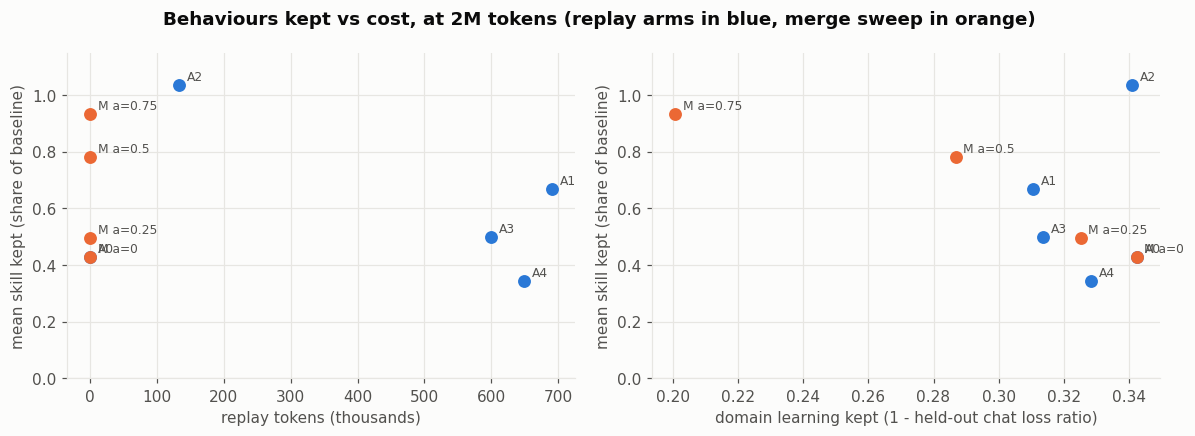

In [4]:
pts = []
for a, R in runs.items():
    r = at(R, T2)
    if r and r.get("skills"):
        sb = R[0]["skills_baseline"]; pts.append((a, r["replay_tokens"], 1 - r["ppl_ratio"], np.mean([r["skills"][KEYS[s]] / sb[KEYS[s]] for s in SK])))
if merge:
    sb = merge[0]["skills_baseline"]
    for r in merge: pts.append((f"M a={r['alpha']:g}", 0, 1 - r["ppl_ratio"], np.mean([r["skills"][KEYS[s]] / sb[KEYS[s]] for s in SK])))
if pts:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, rt, gain, kept in pts:
        col = ORANGE if name.startswith("M") else BLUE
        axes[0].scatter(rt / 1e3, kept, color=col, s=55, zorder=3); axes[0].annotate(name, (rt / 1e3, kept), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK2)
        axes[1].scatter(gain, kept, color=col, s=55, zorder=3); axes[1].annotate(name, (gain, kept), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK2)
    axes[0].set_xlabel("replay tokens (thousands)"); axes[1].set_xlabel("domain learning kept (1 - held-out chat loss ratio)")
    for ax in axes: ax.set_ylabel("mean skill kept (share of baseline)"); ax.set_ylim(0, 1.15)
    fig.suptitle("Behaviours kept vs cost, at 2M tokens (replay arms in blue, merge sweep in orange)", fontweight="bold"); fig.tight_layout(); plt.show()
else: print("no W2 results yet")